# Random Networks: When Does Everything Connect?

Start with 1,000 unconnected nodes and add links between random pairs, 100 at a time. At first the network is
dust: isolated nodes, pairs, the odd chain of three. By the time there are 5,000 links every node can reach every
other. The change is not gradual. Once the mean degree, the average number of links per node c = 2 × links / nodes,
passes 1, a single giant component appears and swallows most of the network within a few more steps.

This is the Erdős–Rényi random graph. It is the reference point for any real network: what you would see if links
formed with no structure at all. The simulation reproduces a set of Python 2 classes from the 2000s (a
`NetBuilder` that adds the links and analyzers for degrees, components and clustering). Here it runs on numpy
and scipy arrays and is checked against the theory:
- **giant component:** for c > 1 a fraction S of the nodes is in one component, where S = 1 − e^(−cS); below 1 there is none
- **degrees:** Poisson with mean c
- **isolated nodes:** a fraction e^(−c)
- **clustering:** two neighbors of a node are linked with probability c / (n − 1), almost never in a large network

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path.cwd().parent))  # project root, so network_dynamics imports without installing
from network_dynamics import graph, growth, theory

COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
INK, MUTED = "#0b0b0b", "#6b6a66"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e6e5e1", "axes.axisbelow": True})

## Growing one network

The 2000s run: 1,000 nodes, 5,000 links, measured after every 100. Each new link joins two different nodes
picked at random, and is redrawn if those two are already linked.

In [2]:
N, M, STEP = 1000, 5000, 100
edges, run = growth.grow(N, M, STEP, rng=7)
run.set_index("links").loc[[100, 300, 500, 700, 1000, 1500, 2000, 3000, 5000]].round(4)

,mean degree,components,largest,largest fraction,second,mean size,isolated,max degree,clustering
links,,,,,,,,,
100,0.2,900,4,0.004,4,1.1111,821,2,0.0000
300,0.6,700,21,0.021,17,1.4286,559,4,0.0000
500,1.0,500,200,0.200,23,2.0000,369,5,0.0000
700,1.4,321,517,0.517,21,3.1153,245,6,0.0000
1000,2.0,168,789,0.789,4,5.9524,138,7,0.0008
1500,3.0,50,945,0.945,4,20.0000,45,10,0.0015
2000,4.0,25,976,0.976,1,40.0000,24,11,0.0040
3000,6.0,5,996,0.996,1,200.0000,4,15,0.0069
5000,10.0,1,1000,1.000,0,1000.0000,0,20,0.0128


At 500 links (c = 1) the largest component has 200 nodes. Another 500 links later it has 789, and at 2,000 links
all but 24 nodes are in it. The number of components falls from 900 to 25 over the same range.

Twenty runs of the same growth, against the theory. The largest component is shown as a fraction of the
nodes. The second largest is shown in nodes: it grows while separate clusters are still forming, peaks at the
transition, and then shrinks because every sizable cluster is eventually absorbed by the giant.

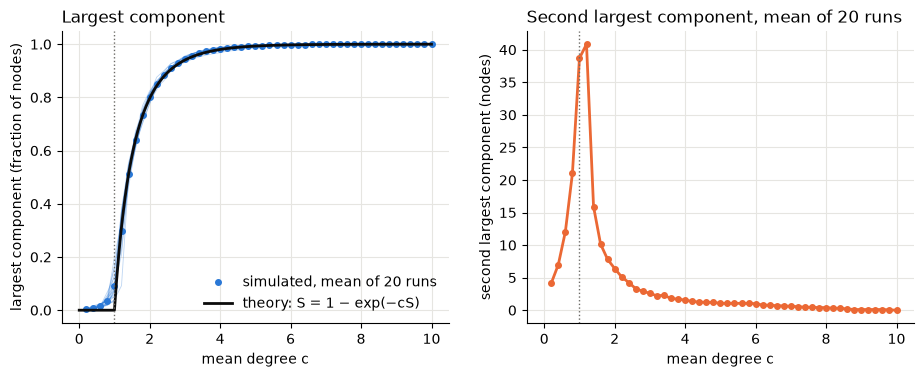

In [3]:
runs = growth.grow_many(N, M, STEP, seeds=range(20))
mean = runs.groupby("mean degree").mean(numeric_only=True)
c = np.linspace(0, 10, 501)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8), sharex=True)
for _, r in runs.groupby("seed"):
    ax1.plot(r["mean degree"], r["largest fraction"], color=COLORS[0], lw=0.6, alpha=0.3)
ax1.plot(mean.index, mean["largest fraction"], "o", color=COLORS[0], ms=4, label="simulated, mean of 20 runs")
ax1.plot(c, theory.giant_fraction(c), color=INK, lw=2, label="theory: S = 1 − exp(−cS)")
ax1.set_ylabel("largest component (fraction of nodes)")
ax1.legend(frameon=False, loc="lower right")
ax2.plot(mean.index, mean["second"], "o-", color=COLORS[1], lw=2, ms=4)
ax2.set_ylabel("second largest component (nodes)")
for ax in (ax1, ax2):
    ax.axvline(1, color=MUTED, lw=1, ls=":")
    ax.set_xlabel("mean degree c")
ax1.set_title("Largest component", loc="left")
ax2.set_title("Second largest component, mean of 20 runs", loc="left")
plt.show()

The simulated giant component tracks the theory everywhere except just above c = 1, where 1,000 nodes is too
few for a sharp transition: the largest cluster already holds about 9% of the nodes at c = 1, where the
infinite-size theory says 0. The second largest component peaks at about 40 nodes, at c ≈ 1.2.

## Degrees

How many nodes have each number of links, at c = 1, 4 and 10, with the Poisson distribution of the same mean.

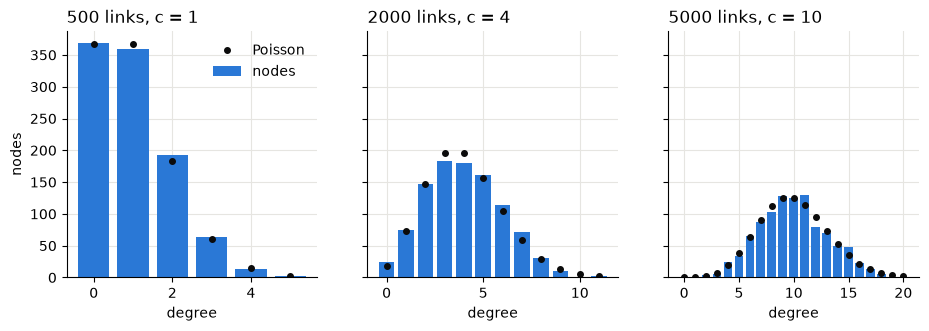

In [4]:
degree_counts = growth.degree_table(N, edges, STEP)
fig, axes = plt.subplots(1, 3, figsize=(11, 3.2), sharey=True)
for ax, links in zip(axes, [500, 2000, 5000]):
    counts = degree_counts.loc[links]
    counts = counts[: counts[counts > 0].index.max() + 1]
    k = counts.index.to_numpy()
    cbar = 2 * links / N
    ax.bar(k, counts, color=COLORS[0], width=0.8, label="nodes")
    ax.plot(k, N * theory.degree_pmf(k, cbar), "o", color=INK, ms=4, label="Poisson")
    ax.set_title(f"{links} links, c = {cbar:.0f}", loc="left")
    ax.xaxis.get_major_locator().set_params(integer=True)
    ax.set_xlabel("degree")
axes[0].set_ylabel("nodes")
axes[0].legend(frameon=False)
plt.show()

The degrees follow the Poisson distribution throughout: most nodes are near the mean and none is far above it
(the largest degree at c = 10 is 20). There are no hubs. That absence is the clearest difference between a random
graph and most real networks, whose degrees have long tails.

## Isolated nodes and clustering

Nodes with no links at all disappear as e^(−c): 37% at c = 1, 2% at c = 4, 0.005% at c = 10.

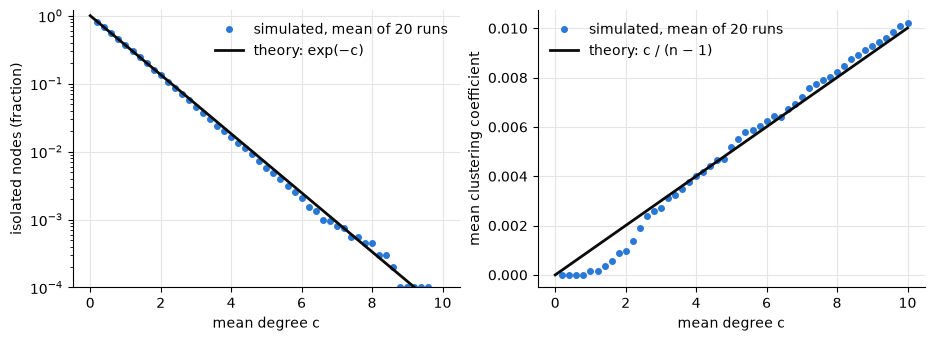

In [5]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.6), sharex=True)
ax1.plot(mean.index, mean["isolated"] / N, "o", color=COLORS[0], ms=4, label="simulated, mean of 20 runs")
ax1.plot(c, theory.isolated_fraction(c), color=INK, lw=2, label="theory: exp(−c)")
ax1.set_yscale("log")
ax1.set_ylim(1e-4, 1.2)
ax1.set_ylabel("isolated nodes (fraction)")
ax1.legend(frameon=False)
ax2.plot(mean.index, mean["clustering"], "o", color=COLORS[0], ms=4, label="simulated, mean of 20 runs")
ax2.plot(c, theory.clustering(c, N), color=INK, lw=2, label="theory: c / (n − 1)")
ax2.set_ylabel("mean clustering coefficient")
ax2.legend(frameon=False)
for ax in (ax1, ax2):
    ax.set_xlabel("mean degree c")
plt.show()

The clustering coefficient of a node is the fraction of pairs of its neighbors that are themselves linked. In a
random graph that is just the overall link density, c / (n − 1): 1% at c = 10 with 1,000 nodes, and it shrinks
as the network grows. Measured social networks, by contrast, have clustering coefficients well above 0.1,
because friends of friends tend to meet. The random graph has none of that.

Below c ≈ 4 the simulated mean falls short of c / (n − 1). Nodes with fewer than two neighbors count as 0 (the
2000s convention), and a sparse random graph has hardly any triangles: about c³ / 6 in expectation, 4.5 at c = 3.

## Bigger networks, sharper transition

The same growth for networks of 100 to 100,000 nodes, five runs each, up to c = 3. The larger the network,
the closer the curve comes to the theory's sharp corner at c = 1.

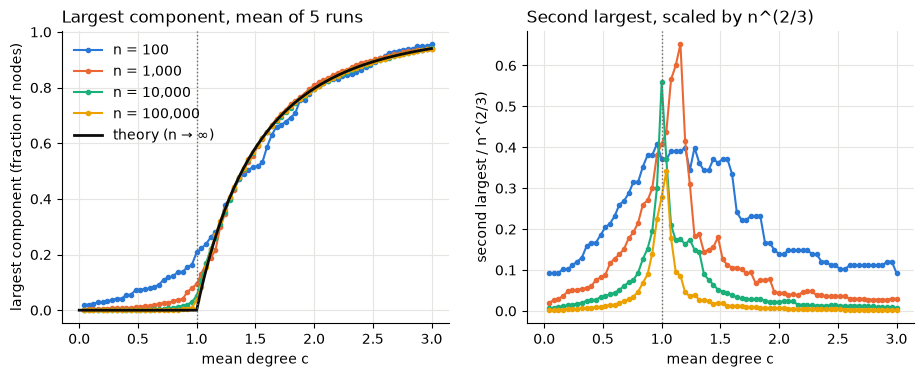

In [6]:
sizes = [100, 1000, 10_000, 100_000]
sweep = pd.concat([growth.grow_many(n, int(1.5 * n), n // 50, seeds=range(5)).assign(n=n) for n in sizes])
c = np.linspace(0, 3, 301)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8), sharex=True)
for n, color in zip(sizes, COLORS):
    m = sweep[sweep["n"] == n].groupby("mean degree").mean(numeric_only=True)
    ax1.plot(m.index, m["largest fraction"], "o-", color=color, lw=1.5, ms=3, label=f"n = {n:,}")
    ax2.plot(m.index, m["second"] / n ** (2 / 3), "o-", color=color, lw=1.5, ms=3, label=f"n = {n:,}")
ax1.plot(c, theory.giant_fraction(c), color=INK, lw=2, label="theory (n → ∞)")
ax1.set_ylabel("largest component (fraction of nodes)")
ax2.set_ylabel("second largest / n^(2/3)")
for ax in (ax1, ax2):
    ax.axvline(1, color=MUTED, lw=1, ls=":")
    ax.set_xlabel("mean degree c")
ax1.legend(frameon=False, loc="upper left")
ax1.set_title("Largest component, mean of 5 runs", loc="left")
ax2.set_title("Second largest, scaled by n^(2/3)", loc="left")
plt.show()

For 100,000 nodes the curve has nearly the theory's corner: below c = 1 the largest component is a vanishing
fraction of the network (3.6% at c = 1 itself), and for 100 nodes it is already 21% there. Above the transition
the sizes agree: at c = 3 all four have 94 to 96% of their nodes in the largest component, against 94.0% from the
theory.

At c = 1 itself the network is critical. Its components have no typical size, and the largest grows as
n^(2/3), faster than the logarithmic sizes below the transition but slower than the linear size above. Scaled by
n^(2/3), the second largest component peaks ever more narrowly as the network grows, and from 10,000 nodes on
the peak is at c = 1 (five runs per size, so the heights are noisy).

The largest component exactly at c = 1 (n/2 links), 20 runs per size, up to a million nodes:

In [7]:
rows = []
for n in [100, 1000, 10_000, 100_000, 1_000_000]:
    largest = [graph.component_sizes(n, graph.random_edges(n, n // 2, rng=s))[0] for s in range(20)]
    rows.append({"nodes": n, "mean largest": np.mean(largest), "median largest": np.median(largest),
                 "n^(2/3)": n ** (2 / 3), "mean / n^(2/3)": np.mean(largest) / n ** (2 / 3),
                 "fraction of nodes": np.mean(largest) / n})
critical = pd.DataFrame(rows).set_index("nodes")
critical.round(3)

,mean largest,median largest,n^(2/3),mean / n^(2/3),fraction of nodes
nodes,,,,,
100,20.00,18.0,21.544,0.928,0.200
1000,76.50,73.0,100.000,0.765,0.076
10000,396.05,340.0,464.159,0.853,0.040
100000,1893.85,1734.0,2154.435,0.879,0.019
1000000,9782.40,7089.5,10000.000,0.978,0.010


The largest component at c = 1 stays near n^(2/3) (0.8 to 1.0 times it) while the nodes grow ten-thousandfold,
so as a fraction of the network it falls from about 20% to 1%.

## Rich get richer: the same number of links, with hubs

In the random graph every link picks its two nodes blindly, so no node gets ahead. In the Barabási–Albert
model, links prefer nodes that already have many. Nodes arrive one at a time and each links to 5 earlier nodes,
picking each with probability proportional to its degree. Six founding nodes start out all linked to each other.
With 1,000 nodes that makes 4,985 links, a mean degree of 10, the same as the end of the 2000s run.

Twenty networks of each kind:

In [8]:
PREF_LINKS = 5
random_k = np.array([graph.degrees(N, graph.random_edges(N, M, rng=s)) for s in range(20)])
pref_k = np.array([graph.degrees(N, graph.preferential_edges(N, PREF_LINKS, rng=s)) for s in range(20)])


def summary(k):
    top = np.sort(k, axis=1)[:, ::-1]
    return {"mean degree": k.mean(), "median degree": np.median(k), "largest degree": k.max(axis=1).mean(),
            "nodes with 30+ links": (k >= 30).mean(axis=1).mean(),
            "top 1% of nodes: share of links": (top[:, : N // 100].sum(axis=1) / top.sum(axis=1)).mean(),
            "top 10% of nodes: share of links": (top[:, : N // 10].sum(axis=1) / top.sum(axis=1)).mean()}


pd.DataFrame({"random": summary(random_k), "rich get richer": summary(pref_k)}).round(3)

,random,rich get richer
mean degree,10.000,9.970
median degree,10.000,7.000
largest degree,21.550,116.250
nodes with 30+ links,0.000,0.036
top 1% of nodes: share of links,0.019,0.085
top 10% of nodes: share of links,0.159,0.330


Same nodes, nearly the same number of links, a very different network. The best-connected node has about 116
links instead of 22. The top 1% of nodes hold 8.5% of the link ends instead of 1.9%, and the median node has
fewer links (7) than in the random graph (10). The tail is a power law. The share of nodes with at least k links
falls as m(m + 1) / (k(k + 1)), roughly k^-2, while the random graph's Poisson tail falls faster than any power.
Past about 100 links the measured tail drops below the k^-2 line: with 1,000 nodes there is not enough network
for larger hubs to form.

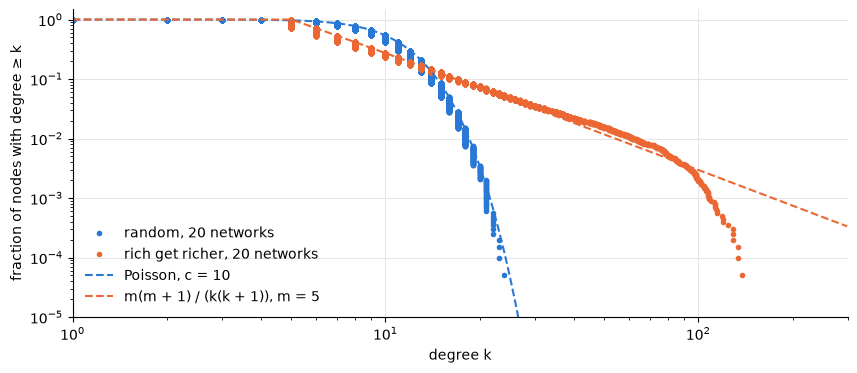

In [9]:
fig, ax = plt.subplots(figsize=(10, 4))
k = np.arange(1, 300)
for degrees, color, label in [(random_k, COLORS[0], "random"), (pref_k, COLORS[1], "rich get richer")]:
    values = np.sort(degrees.ravel())
    share = 1 - np.arange(len(values)) / len(values)  # fraction of nodes with at least this degree
    ax.plot(values, share, "o", color=color, ms=3, label=f"{label}, 20 networks")
ax.plot(k, theory.degree_ccdf(k, 2 * M / N), color=COLORS[0], lw=1.5, ls="--", label="Poisson, c = 10")
ax.plot(k, theory.preferential_ccdf(k, PREF_LINKS), color=COLORS[1], lw=1.5, ls="--",
        label="m(m + 1) / (k(k + 1)), m = 5")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlim(1, 300)
ax.set_ylim(1e-5, 1.5)
ax.set_xlabel("degree k")
ax.set_ylabel("fraction of nodes with degree ≥ k")
ax.legend(frameon=False, loc="lower left")
plt.show()

Who becomes a hub? Not a random node, as with the giant component, and not the best one: the oldest. A node that
arrives early has more time to collect links, and every link it gets makes the next more likely. The node that
arrived i-th of n ends with about m √(n / i) links. Mean degree by order of arrival, over the 20 networks:

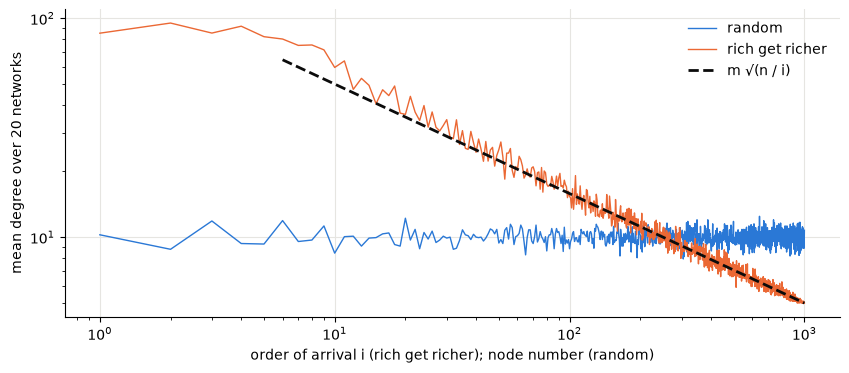

arrival order of the node with the most links, in each network: [1, 1, 1, 1, 2, 2, 2, 2, 2, 4, 4, 5, 6, 6, 6, 6, 8, 11, 13, 16]


In [10]:
arrival = np.arange(1, N + 1)
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(arrival, random_k.mean(axis=0), color=COLORS[0], lw=1, label="random")
ax.plot(arrival, pref_k.mean(axis=0), color=COLORS[1], lw=1, label="rich get richer")
ax.plot(arrival[PREF_LINKS:], theory.preferential_degree(arrival[PREF_LINKS:], N, PREF_LINKS), color=INK, lw=2,
        ls="--", label="m √(n / i)")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("order of arrival i (rich get richer); node number (random)")
ax.set_ylabel("mean degree over 20 networks")
ax.legend(frameon=False)
plt.show()
print("arrival order of the node with the most links, in each network:",
      sorted(int(i) + 1 for i in pref_k.argmax(axis=1)))

In every one of the 20 networks the hub is among the first 16 nodes to arrive. The six founders, linked to each
other from the start, end with 80 to 95 links each. From the 50th arrival on, degrees follow m √(n / i): 22 for
the 50th node, 7 for the 500th, 5 (its own links) for the last.

## The takeaway: one giant, no hubs

"Winner takes all" fits the random graph only for components. Above c = 1 there is exactly one giant, and every
sizable cluster is eventually absorbed into it, because a new link lands on a cluster in proportion to its size.
Which cluster wins is chance. The nodes never get winners: degrees stay Poisson, and the best-connected node has
about twice the average.

Rich get richer is what produces winners among nodes: a power-law tail, hubs with ten times the average, and
the hubs are the oldest nodes. Real networks (the web, citations, airline routes) look like this, not like the
random graph. The random graph is the baseline that shows how much of that structure comes from how links are
chosen.

## Notes

- The package reproduces the 2000s classes (`NetBuilder`, `NetAnalyzer`, `NodeTreeAnalyzer`,
  `NodeNeighborhoodAnalyzer`) run under Python 3. Fed the same 5,000 links, both give the same links, degree
  histogram, components, component sizes and mean component size at every step, and the same mean clustering
  coefficient to 2e-17. The tests check the values at four steps.
- The rich-get-richer network is not in the 2000s code; it was added in 2026 for comparison.
- The 2000s code reported `avg_links`, links per node, which is half the mean degree used here.
- The 2000s code picked node ids with `random.randint(0, n)`, which can return 0, but the ids ran from 1 to n.
  A draw of 0 failed to link and was retried, so every pair of nodes was still equally likely.